# Partie vidéo — reconnaissance d'émotions sur des clips de films

**Objectif** : prédire l'émotion d'un clip (8 classes) à partir de ses images seulement, et produire une probabilité
par classe pour chaque clip. Ces probabilités seront fusionnées avec celles des branches texte et audio.

Classes : `amusement`, `awe`, `contentment`, `excitement` (valence positive) ; `anger`, `disgust`, `fear`, `sadness` (valence négative).

**Workflow de départ pour vidéo** (choisi par le groupe à partir de nos recherches) :

```
VIDÉO ──► 8–16 images uniformes ──► CLIP ViT-L/14 (gelé) ──► moyenne + écart-type ──► classifieur ──► probabilités (fusion)
```

Ce pipeline est comparé à des variantes (métadonnées, mouvement, GRU, ensemble). Le modèle final est choisi en section 7
par une règle fixée à l'avance et calculée uniquement sur le train : la règle d'un écart-type.

**Protocole d'évaluation** :
- les splits train / dev / test séparent les **films** : aucun film n'apparaît dans deux splits ;
- **tous les choix** (hyperparamètres, nombre d'époques, modèle) se font par **validation croisée groupée
  par film** (`GroupKFold`, 5 plis) sur le train ;
- le **dev** et le **test** servent uniquement à mesurer. Chaque score est donné avec un intervalle de confiance à 95 %
  (bootstrap sur les films) ;
- mesure principale : **F1 macro** (classes déséquilibrées : anger 22 % des clips, amusement 8 %). On donne aussi
  l'exactitude et la valence (positif / négatif).


**Plan** :

0. Configuration
1. Chargement des annotations et vérifications
2. Baseline : métadonnées
3. Extraction des images et des embeddings CLIP ViT-L/14
4. Modèle du workflow : CLIP (moyenne + écart-type) → régression logistique
5. Analyse des erreurs
6. Exploiter le temps : mouvement et GRU
7. Comparaison des modèles et choix du modèle final
8. Sauvegarde des probabilités pour la fusion
9. Bilan par rapport aux cibles


## 0. Configuration

In [ ]:
import os, sys, json, shutil, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# Organisation des données :
#   movie/annotation/<film>/<video_id>.json   (un fichier JSON par clip)
#   movie/video/<film>/<video_id>.mp4
# (le dossier movie/ compressé). Lire des milliers de petits fichiers directement sur Drive
# est très lent (> 20 min) : on décompresse donc movie.zip sur le disque local /content.
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/PROJET_SID_2026") if IN_COLAB else Path(".")

if IN_COLAB:
    MOVIE_DIR = Path("/content/movie")
    if not MOVIE_DIR.exists():                    # disque local effacé à chaque session
        zip_path = DATA_DIR / "movie.zip"
        if zip_path.exists():
            print("Copie et décompression de movie.zip sur /content ...")
            shutil.copy(zip_path, "/content/movie.zip")   # un seul gros fichier : rapide
            subprocess.run(["unzip", "-q", "-o", "/content/movie.zip", "-d", "/content"], check=True)
            os.remove("/content/movie.zip")
        else:
            print("movie.zip absent du Drive : copie du dossier movie/ (lent, une fois par session)")
            shutil.copytree(DATA_DIR / "movie", MOVIE_DIR)
    assert (MOVIE_DIR / "annotation").exists(), \
        f"{MOVIE_DIR}/annotation introuvable : movie.zip doit contenir le dossier movie/ à sa racine"
else:
    MOVIE_DIR = DATA_DIR / "movie"
VIDEO_DIR = MOVIE_DIR / "video"                             # dossier des .mp4
ANNOT_DIR = MOVIE_DIR / "annotation"                        # annotations, une par clip
SPLIT_DIR = DATA_DIR / "splits"                             # découpage commun aux 3 branches
SPLIT_FILES = {                                             # un identifiant de film par ligne
    "train": SPLIT_DIR / "train.txt",
    "dev":   SPLIT_DIR / "dev.txt",
    "test":  SPLIT_DIR / "test.txt",
}
CACHE_DIR = DATA_DIR / "cache_video"     # embeddings CLIP sauvegardés ici (sur Drive : conservés)
OUT_DIR = DATA_DIR / "outputs_video"     # probabilités pour la fusion
for d in (SPLIT_DIR, CACHE_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

N_FRAMES = 8          # images échantillonnées uniformément par clip (le workflow autorise 8 à 16)
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["amusement", "awe", "contentment", "excitement",
           "anger", "disgust", "fear", "sadness"]
EVAL_SPLITS = ["dev", "test"]   # jeux de mesure uniquement : aucun choix n'est fait sur eux
print("Device :", DEVICE)

Mounted at /content/drive
Copie et décompression de movie.zip sur /content ...
Device : cuda


## 1. Chargement des annotations et vérifications

In [ ]:
def load_split(path):
    # Le fichier de split liste des films ; on charge tous les clips de ces films
    films = [l.strip() for l in Path(path).read_text(encoding="utf-8-sig").splitlines() if l.strip()]
    records, erreurs = [], []
    for film in films:
        for chemin in sorted((ANNOT_DIR / film).glob("*.json")):
            try:
                with open(chemin, encoding="utf-8") as f:
                    records.append(json.load(f))
            except (json.JSONDecodeError, UnicodeDecodeError):
                erreurs.append(chemin.name)
    if erreurs:
        print(f"{Path(path).name} : {len(erreurs)} JSON illisibles ignorés", erreurs[:3])
    if not records:
        raise FileNotFoundError(
            f"Aucun clip trouvé pour {Path(path).name} : vérifier que {ANNOT_DIR.resolve()} "
            f"existe et contient les dossiers de films (ex. {films[0] if films else '?'}/*.json)")
    return pd.DataFrame(records)

dfs = {split: load_split(p) for split, p in SPLIT_FILES.items()}
for split, df in dfs.items():
    df["split"] = split
    df["film_id"] = df["video_id"].str.split("_").str[0]   # "00000_clip_001" -> "00000"
    print(split, df.shape)

dfs["train"].head()

train (2207, 9)
dev (442, 9)
test (439, 9)


,video_id,brightness,colorfulness,hue,emotion,caption,duration,split,film_id
0,00002_clip_004,0.1,0.7,24,contentment,The video shows a man with long hair and a mus...,4.80,train,00002
1,00002_clip_006,0.1,0.7,26,awe,"The video shows a woman with long dark hair, w...",7.88,train,00002
2,00002_clip_007,0.1,0.6,21,anger,The video shows a man holding a knife in a roo...,15.60,train,00002
3,00002_clip_008,0.1,0.7,21,anger,The video depicts a scene from a movie featuri...,13.09,train,00002
4,00002_clip_011,0.1,0.7,21,anger,The video shows a woman with dark hair and a r...,4.71,train,00002


In [ ]:
# Vérification 1 : un même film apparaît-il dans plusieurs splits ?
films = {s: set(df["film_id"]) for s, df in dfs.items()}
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    inter = films[a] & films[b]
    print(f"Films communs {a}/{b} : {len(inter)}")

Films communs train/dev : 0
Films communs train/test : 0
Films communs dev/test : 0


In [ ]:
# Vérification 2 : répartition des classes dans chaque split
for split, df in dfs.items():
    print(f"\n--- {split} ---")
    print(df["emotion"].value_counts(normalize=True).round(3))

# Vérification 3 : tous les fichiers vidéo existent-ils ?
def video_path(vid):
    # movie/video/<film>/<video_id>.mp4 : "00000_clip_001" -> video/00000/00000_clip_001.mp4
    return VIDEO_DIR / vid.split("_")[0] / f"{vid}.mp4"

for split, df in dfs.items():
    missing = [v for v in df["video_id"] if not video_path(v).exists()]
    print(f"{split} : {len(missing)} vidéos introuvables", missing[:3])


--- train ---
emotion
anger          0.219
fear           0.168
contentment    0.120
excitement     0.114
sadness        0.111
disgust        0.096
awe            0.093
amusement      0.079
Name: proportion, dtype: float64

--- dev ---
emotion
anger          0.222
fear           0.167
contentment    0.122
excitement     0.115
sadness        0.106
disgust        0.097
awe            0.090
amusement      0.079
Name: proportion, dtype: float64

--- test ---
emotion
anger          0.219
fear           0.169
contentment    0.123
excitement     0.116
sadness        0.105
disgust        0.098
awe            0.091
amusement      0.080
Name: proportion, dtype: float64
train : 0 vidéos introuvables []
dev : 0 vidéos introuvables []
test : 0 vidéos introuvables []


## 2. Baseline : métadonnées

Chaque clip est annoté avec des métadonnées visuelles : luminosité (`brightness`), saturation (`colorfulness`),
teinte (`hue`) et durée. Cette baseline sert de point de comparaison pour les modèles fondés sur CLIP.

Le `hue` est un **angle** (0 et 359 sont voisins) : on l'encode en `sin` / `cos`.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, accuracy_score, classification_report

# Le hue va de 0 à 359 (valeurs entières) : ce sont des degrés (0-360), pas l'échelle 0-180 d'OpenCV.
print("hue min/max :", dfs["train"]["hue"].min(), dfs["train"]["hue"].max())
HUE_MAX = 360.0

def meta_features(df):
    angle = 2 * np.pi * df["hue"].values / HUE_MAX
    return np.column_stack([
        df["brightness"].values,
        df["colorfulness"].values,
        np.sin(angle), np.cos(angle),
        df["duration"].values,
    ]).astype(np.float32)

label2id = {c: i for i, c in enumerate(CLASSES)}
def labels(df):
    return df["emotion"].map(label2id).values

X_meta = {s: meta_features(df) for s, df in dfs.items()}
y = {s: labels(df) for s, df in dfs.items()}

clf_meta = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=2000, class_weight="balanced"))
clf_meta.fit(X_meta["train"], y["train"])
pred = clf_meta.predict(X_meta["dev"])
print("Métadonnées seules — dev F1 macro :", round(f1_score(y["dev"], pred, average="macro"), 4))
print("Hasard (8 classes) ≈ 0.125")

hue min/max : 0 359
Métadonnées seules — dev F1 macro : 0.0984
Hasard (8 classes) ≈ 0.125


In [ ]:
# Pourquoi les métadonnées font moins bien que le hasard ?
# Part de la variance expliquée par le film (eta²) : proche de 1 = la variable décrit le film,
# pas la scène. Comme les splits séparent les films, une telle variable ne peut pas se généraliser.
# (le hue est un angle : l'eta² est approximatif pour lui)
all_df = pd.concat(dfs.values(), ignore_index=True)
for col in ["brightness", "colorfulness", "hue", "duration"]:
    total = all_df[col].var(ddof=0)
    intra = all_df.groupby("film_id")[col].transform(lambda v: v - v.mean()).pow(2).mean()
    print(f"{col:13s} part de variance due au film = {1 - intra / total:.2f}")

brightness    part de variance due au film = 0.72
colorfulness  part de variance due au film = 0.75
hue           part de variance due au film = 0.60
duration      part de variance due au film = 0.20


## 3. Extraction des images et des embeddings CLIP ViT-L/14 (gelé)

Étapes 1 à 3 du workflow : `VIDÉO → N_FRAMES images uniformes → CLIP ViT-L/14 gelé`.
CLIP n'est **pas** ré-entraîné : il sert uniquement d'extracteur de features (aucun gradient).
Chaque image donne un embedding de dimension 768, normalisé (norme L2 = 1).

À exécuter **une fois** avec un GPU (~45 min avec 8 images par clip, le double avec 16).
Les embeddings sont sauvegardés dans `cache_video/` (`clip_clip-vit-large-patch14_<split>_<N_FRAMES>f.npz`) :
ensuite tout le reste peut tourner sur CPU.

In [ ]:
import cv2
from PIL import Image

def sample_frames(path, n=N_FRAMES):
    # Échantillonne n images réparties uniformément sur le clip (en RGB)
    cap = cv2.VideoCapture(str(path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames = []
    if total > 0:
        idxs = np.linspace(0, total - 1, n).round().astype(int)
        for i in idxs:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
            ok, frame = cap.read()
            if ok:
                frames.append(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    cap.release()
    # Complète si certaines images n'ont pas pu être lues
    while 0 < len(frames) < n:
        frames.append(frames[-1])
    return frames   # liste vide si la vidéo est illisible

# Test rapide sur un clip
test_frames = sample_frames(video_path(dfs["train"]["video_id"].iloc[0]))
print(len(test_frames), "images", test_frames[0].size if test_frames else "")

8 images (1280, 720)


In [ ]:
from transformers import CLIPModel, CLIPProcessor
from tqdm.auto import tqdm

CLIP_NAME = "openai/clip-vit-large-patch14"
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_model.requires_grad_(False)             # CLIP gelé : simple extracteur de features
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
EMB_DIM = clip_model.config.projection_dim   # 768 pour ViT-L/14
print(f"{CLIP_NAME} : embeddings de dimension {EMB_DIM}, {N_FRAMES} images par clip")

# Projection faite à la main : selon la version de transformers, get_image_features
# ne renvoie pas toujours un tenseur.
def image_features(inputs):
    pooled = clip_model.vision_model(pixel_values=inputs["pixel_values"]).pooler_output
    return clip_model.visual_projection(pooled)

@torch.no_grad()
def extract_split(split):
    out_path = CACHE_DIR / f"clip_{CLIP_NAME.split('/')[-1]}_{split}_{N_FRAMES}f.npz"
    df = dfs[split]
    if out_path.exists():
        cached = np.load(out_path, allow_pickle=True)
        # Le cache doit suivre exactement l'ordre des clips du DataFrame
        assert (cached["ids"] == df["video_id"].values).all(), f"{out_path.name} : ordre des clips différent"
        print(f"{split} : déjà en cache")
        return cached["emb"]
    emb = np.zeros((len(df), N_FRAMES, EMB_DIM), dtype=np.float32)
    failed = []
    for k, vid in enumerate(tqdm(df["video_id"], desc=split)):
        frames = sample_frames(video_path(vid))
        if not frames:
            failed.append(vid)
            continue
        inputs = clip_proc(images=frames, return_tensors="pt").to(DEVICE)
        # Demi-précision sur GPU pour accélérer l'extraction
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            f = image_features(inputs).float()
        f = f / f.norm(dim=-1, keepdim=True)          # normalisation L2
        emb[k] = f.cpu().numpy()
    np.savez_compressed(out_path, emb=emb, ids=df["video_id"].values)
    print(f"{split} : {len(failed)} vidéos illisibles", failed[:3])
    return emb

EMB = {s: extract_split(s) for s in dfs}   # forme : (n_clips, N_FRAMES, EMB_DIM)

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

openai/clip-vit-large-patch14 : embeddings de dimension 768, 8 images par clip
train : déjà en cache
dev : déjà en cache
test : déjà en cache


## 4. Modèle du workflow : CLIP (moyenne + écart-type) → régression logistique

Étape 4 du workflow : les `N_FRAMES` embeddings d'un clip sont résumés par leur **moyenne** (contenu de la scène)
et leur **écart-type** (variation dans le temps) → vecteur de 2 × 768 = 1536 dimensions, puis régression logistique.

Hyperparamètres choisis par validation croisée groupée par film sur le train :
- `C` (force de la régularisation) ;
- la **pondération des classes** : `balanced` (poids inversement proportionnels aux fréquences), `sqrt` (racine carrée
  de ces poids, un compromis) ou `None` (aucune pondération).

Règle de choix : parmi les réglages dont le F1 macro CV est à moins d'une erreur-type du meilleur (différence plus petite
que le bruit entre plis), on retient celui qui a la meilleure **exactitude CV**. Ce choix ne regarde ni le dev ni le test.

La variante « + métadonnées » est testée à titre de comparaison.

In [ ]:
from sklearn.model_selection import GroupKFold, GridSearchCV

# Validation croisée groupée par film sur le train : sert à TOUS les choix.
CV = GroupKFold(n_splits=5)
groups_train = dfs["train"]["film_id"].values

def f1_ci(y_true, y_pred, groups, n_boot=1000, seed=SEED):
    # F1 macro + intervalle de confiance à 95 % par bootstrap sur les FILMS
    # (les clips d'un même film sont corrélés : rééchantillonner les clips sous-estimerait l'incertitude)
    rng = np.random.default_rng(seed)
    films = np.unique(groups)
    idx_by_film = {f: np.flatnonzero(groups == f) for f in films}
    scores = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_film[f] for f in rng.choice(films, size=len(films))])
        scores.append(f1_score(y_true[idx], y_pred[idx], average="macro", zero_division=0))
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return f1_score(y_true, y_pred, average="macro"), lo, hi

# Pondération intermédiaire : racine carrée des poids « balanced » n / (k * n_classe)
_counts = np.bincount(y["train"], minlength=len(CLASSES))
CW_SQRT = {k: float(np.sqrt(len(y["train"]) / (len(CLASSES) * _counts[k]))) for k in range(len(CLASSES))}

def cw_name(cw):
    return "sqrt" if isinstance(cw, dict) else str(cw)

def choose_f1_then_acc(res):
    # Meilleure exactitude CV parmi les réglages à moins d'une erreur-type du meilleur F1 macro CV
    f1, acc = res["mean_test_f1"], res["mean_test_acc"]
    best = int(np.argmax(f1))
    se = res["std_test_f1"][best] / np.sqrt(CV.n_splits)
    ok = np.flatnonzero(f1 >= f1[best] - se)
    return int(ok[np.argmax(acc[ok])])

def fit_logreg(X, Cs=(0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1),
               class_weights=("balanced", CW_SQRT, None)):
    # Choix de C et de la pondération par CV groupée sur le train, puis réentraînement sur tout le train
    pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    grid = GridSearchCV(pipe, {"logisticregression__C": list(Cs),
                               "logisticregression__class_weight": list(class_weights)},
                        scoring={"f1": "f1_macro", "acc": "accuracy"}, refit=choose_f1_then_acc, cv=CV, n_jobs=-1)
    grid.fit(X["train"], y["train"], groups=groups_train)
    res, i = grid.cv_results_, grid.best_index_
    f1, lo, hi = f1_ci(y["dev"], grid.predict(X["dev"]), dfs["dev"]["film_id"].values)
    print(f"  paramètres : C = {grid.best_params_['logisticregression__C']}, "
          f"class_weight = {cw_name(grid.best_params_['logisticregression__class_weight'])}")
    if grid.best_params_["logisticregression__C"] in (min(Cs), max(Cs)):
        print("  ATTENTION : C retenu au bord de la grille, l'optimum est peut-être en dehors")
    print(f"  F1 macro CV = {res['mean_test_f1'][i]:.4f} (écart-type entre plis {res['std_test_f1'][i]:.3f}), "
          f"exactitude CV = {res['mean_test_acc'][i]:.4f}   |   dev = {f1:.4f}  IC95 [{lo:.3f}, {hi:.3f}]")
    return grid.best_estimator_, grid.best_params_, res["mean_test_f1"][i]

def pooled_features(emb):
    # Workflow : (n_clips, N_FRAMES, 768) -> moyenne (768) + écart-type (768) sur le temps
    return np.concatenate([emb.mean(axis=1), emb.std(axis=1)], axis=1)

X_clip = {s: pooled_features(EMB[s]) for s in dfs}
print("Dimension des features :", X_clip["train"].shape[1])
print("CLIP (moyenne + écart-type) — modèle du workflow :")
clf_clip, params_clip, cv_clip = fit_logreg(X_clip)

# Comparaison : ajouter les métadonnées apporte-t-il quelque chose ?
X_clip_meta = {s: np.concatenate([X_clip[s], X_meta[s]], axis=1) for s in dfs}
print("\nCLIP + méta (comparaison) :")
clf_clip_meta, params_clip_meta, cv_clip_meta = fit_logreg(X_clip_meta)

Dimension des features : 1536
CLIP (moyenne + écart-type) — modèle du workflow :
  paramètres : C = 0.001, class_weight = sqrt
  F1 macro CV = 0.3624 (écart-type entre plis 0.040), exactitude CV = 0.4042   |   dev = 0.3897  IC95 [0.306, 0.447]

CLIP + méta (comparaison) :
  paramètres : C = 0.001, class_weight = sqrt
  F1 macro CV = 0.3648 (écart-type entre plis 0.040), exactitude CV = 0.4069   |   dev = 0.3900  IC95 [0.310, 0.447]


## 5. Analyse des erreurs (modèle du workflow, sur le dev)

              precision    recall  f1-score   support

   amusement      0.472     0.486     0.479        35
         awe      0.375     0.375     0.375        40
 contentment      0.333     0.574     0.422        54
  excitement      0.476     0.196     0.278        51
       anger      0.461     0.357     0.402        98
     disgust      0.160     0.186     0.172        43
        fear      0.531     0.581     0.555        74
     sadness      0.444     0.426     0.435        47

    accuracy                          0.405       442
   macro avg      0.407     0.398     0.390       442
weighted avg      0.421     0.405     0.400       442



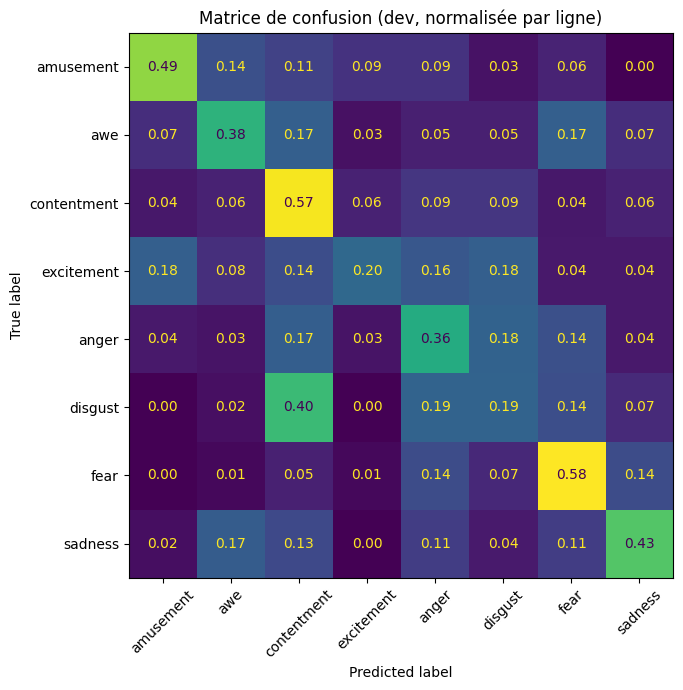

Valence correcte : 72.4%  (prédire toujours « négatif » donnerait 59.3%)
  amusement    prédictions dans la bonne valence : 83%
  awe          prédictions dans la bonne valence : 65%
  contentment  prédictions dans la bonne valence : 72%
  excitement   prédictions dans la bonne valence : 59%
  anger        prédictions dans la bonne valence : 72%
  disgust      prédictions dans la bonne valence : 58%
  fear         prédictions dans la bonne valence : 92%
  sadness      prédictions dans la bonne valence : 68%

Nb prédit / nb réel : {'amusement': 1.03, 'awe': 1.0, 'contentment': 1.72, 'excitement': 0.41, 'anger': 0.78, 'disgust': 1.16, 'fear': 1.09, 'sadness': 0.96}


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

pred_dev = clf_clip.predict(X_clip["dev"])
print(classification_report(y["dev"], pred_dev, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y["dev"], pred_dev, display_labels=CLASSES,
                                        normalize="true", ax=ax, values_format=".2f",
                                        xticks_rotation=45, colorbar=False)
plt.title("Matrice de confusion (dev, normalisée par ligne)")
plt.tight_layout(); plt.show()

# Les confusions restent-elles dans un même groupe de valence ?
# (positif : amusement, awe, contentment, excitement / négatif : anger, disgust, fear, sadness)
VALENCE = np.array([1 if c in ("amusement", "awe", "contentment", "excitement") else 0 for c in CLASSES])
same_valence = VALENCE[y["dev"]] == VALENCE[pred_dev]
print(f"Valence correcte : {same_valence.mean():.1%}  "
      f"(prédire toujours « négatif » donnerait {1 - VALENCE[y['dev']].mean():.1%})")
for k, c in enumerate(CLASSES):
    print(f"  {c:12s} prédictions dans la bonne valence : {same_valence[y['dev'] == k].mean():.0%}")

# Classes « aimants » : prédites beaucoup plus souvent qu'elles n'apparaissent
ratio = np.bincount(pred_dev, minlength=len(CLASSES)) / np.bincount(y["dev"], minlength=len(CLASSES))
print("\nNb prédit / nb réel :", {c: round(float(r), 2) for c, r in zip(CLASSES, ratio)})

## 6. Exploiter le temps

Le résumé moyenne + écart-type ignore l'ordre des images. Deux pistes pour en tenir compte :

**a) Features de mouvement** : calculées à partir des embeddings, sans relire les vidéos.
**b) Un petit GRU bidirectionnel** sur la séquence `(N_FRAMES, 768)`.

Sur des clips de quelques secondes, le résumé moyenne + écart-type peut suffire : un gain nul est aussi un résultat.

In [ ]:
# a) Features de mouvement
def motion_features(emb):
    # emb : (n_clips, N_FRAMES, EMB_DIM), déjà normalisés
    # Similarité cosinus entre images consécutives -> (n_clips, N_FRAMES-1)
    # Une faible similarité = beaucoup de changement (mouvement, changement de plan)
    sim = (emb[:, 1:] * emb[:, :-1]).sum(axis=2)
    first_last = (emb[:, 0] * emb[:, -1]).sum(axis=1)   # le clip finit-il loin de son début ?
    return np.column_stack([
        sim.mean(axis=1), sim.std(axis=1), sim.min(axis=1), sim.max(axis=1),
        (sim < 0.8).sum(axis=1),        # nombre de changements de plan probables
        first_last,
    ]).astype(np.float32)

X_motion = {s: np.concatenate([X_clip[s], motion_features(EMB[s])], axis=1) for s in dfs}
print("CLIP + mouvement :")
clf_motion, params_motion, cv_motion = fit_logreg(X_motion)
print(f"\nPour comparaison, CLIP seul : F1 macro CV = {cv_clip:.4f}")

CLIP + mouvement :
  paramètres : C = 0.001, class_weight = balanced
  F1 macro CV = 0.3721 (écart-type entre plis 0.025), exactitude CV = 0.4046   |   dev = 0.3915  IC95 [0.312, 0.447]

Pour comparaison, CLIP seul : F1 macro CV = 0.3624


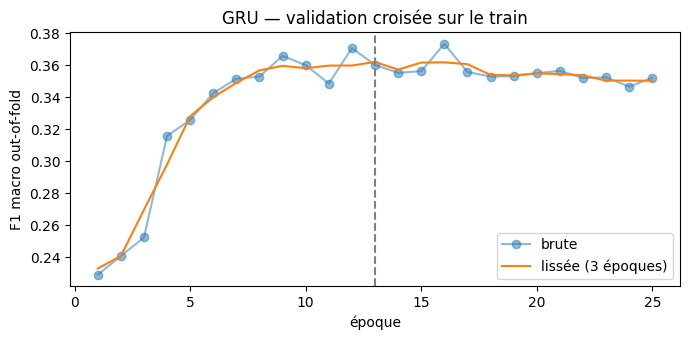

Époque retenue : 13
GRU (5 graines) — dev F1 macro = 0.4085  IC95 [0.330, 0.462]


In [ ]:
# b) Modèle temporel GRU
#  - nombre d'époques choisi par validation croisée groupée par film sur le train, sur la courbe F1
#    out-of-fold lissée (on choisit un plateau, pas un pic isolé dû au hasard) ;
#  - score CV calculé pli par pli avec une époque choisie SANS le pli évalué (sélection imbriquée) ;
#  - modèle final : ensemble de N_SEEDS GRU (moyenne des probabilités) pour réduire la variance.
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

class TemporalGRU(nn.Module):
    def __init__(self, in_dim=768, hidden=128, n_classes=8, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(in_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):                 # x : (batch, N_FRAMES, EMB_DIM)
        out, _ = self.gru(x)              # (batch, N_FRAMES, 2*hidden)
        pooled = out.mean(dim=1)          # moyenne sur le temps
        return self.head(self.drop(pooled))

GRU_HIDDEN, GRU_DROPOUT = 64, 0.5         # petit modèle très régularisé : peu de données
N_EPOCHS, N_SEEDS = 25, 5

def make_loader(emb, labels=None, shuffle=False, batch_size=64):
    labels = np.zeros(len(emb), dtype=np.int64) if labels is None else labels
    ds = TensorDataset(torch.from_numpy(emb), torch.from_numpy(np.asarray(labels)).long())
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

@torch.no_grad()
def predict_proba_gru(model, emb):
    model.eval()
    return torch.cat([torch.softmax(model(xb.to(DEVICE)), dim=1).cpu()
                      for xb, _ in make_loader(emb, batch_size=256)]).numpy()

def train_gru(emb_tr, y_tr, n_epochs, seed, emb_val=None):
    # Entraîne n_epochs époques ; renvoie le modèle final et, si emb_val est fourni,
    # les probabilités sur emb_val après chaque époque : (n_epochs, n_val, n_classes)
    torch.manual_seed(seed)
    # Poids inverses aux fréquences : n / (k * n_classe), comme class_weight="balanced"
    counts = np.bincount(y_tr, minlength=len(CLASSES))
    class_w = torch.tensor(len(y_tr) / (len(CLASSES) * np.maximum(counts, 1)), dtype=torch.float32)
    model = TemporalGRU(EMB_DIM, GRU_HIDDEN, len(CLASSES), GRU_DROPOUT).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_w.to(DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    val_probs = []
    for _ in range(n_epochs):
        model.train()
        for xb, yb in make_loader(emb_tr, y_tr, shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            criterion(model(xb), yb).backward()
            optimizer.step()
        if emb_val is not None:
            val_probs.append(predict_proba_gru(model, emb_val))
    return model, np.array(val_probs)

# Étape 1 : probabilités out-of-fold après chaque époque (validation croisée groupée par film)
oof_by_epoch = np.zeros((N_EPOCHS, len(y["train"]), len(CLASSES)), dtype=np.float32)
fold_of = np.empty(len(y["train"]), dtype=int)       # numéro du pli de validation de chaque clip
for k, (tr, va) in enumerate(CV.split(EMB["train"], y["train"], groups_train)):
    _, probs = train_gru(EMB["train"][tr], y["train"][tr], N_EPOCHS, SEED + k, EMB["train"][va])
    oof_by_epoch[:, va] = probs
    fold_of[va] = k

def smooth(curve):
    # Moyenne glissante sur 3 époques
    return np.convolve(np.pad(curve, 1, mode="edge"), np.ones(3) / 3, mode="valid")

def choose_epoch(mask):
    # Courbe F1 out-of-fold restreinte aux clips de mask -> époque du maximum de la courbe lissée
    curve = np.array([f1_score(y["train"][mask], p[mask].argmax(axis=1), average="macro") for p in oof_by_epoch])
    return int(smooth(curve).argmax()) + 1, curve

# Époque des modèles finaux (entraînés sur tout le train) : choisie sur tous les plis
BEST_EPOCH, cv_curve = choose_epoch(np.ones(len(y["train"]), dtype=bool))

# Score CV : pour chaque pli k, l'époque est choisie sur les 4 autres plis, puis le pli k est évalué
# à cette époque. Ces probabilités out-of-fold servent aussi à la comparaison et à l'ensemble.
OOF_GRU = np.zeros((len(y["train"]), len(CLASSES)), dtype=np.float32)
for k in range(CV.n_splits):
    e_k, _ = choose_epoch(fold_of != k)
    OOF_GRU[fold_of == k] = oof_by_epoch[e_k - 1, fold_of == k]

plt.figure(figsize=(7, 3.5))
plt.plot(range(1, N_EPOCHS + 1), cv_curve, marker="o", alpha=0.5, label="brute")
plt.plot(range(1, N_EPOCHS + 1), smooth(cv_curve), label="lissée (3 époques)")
plt.axvline(BEST_EPOCH, ls="--", c="grey")
plt.xlabel("époque"); plt.ylabel("F1 macro out-of-fold"); plt.title("GRU — validation croisée sur le train")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Époque retenue : {BEST_EPOCH}")

# Étape 2 : N_SEEDS modèles entraînés sur tout le train pendant BEST_EPOCH époques
gru_models = [train_gru(EMB["train"], y["train"], BEST_EPOCH, SEED + 100 + s)[0] for s in range(N_SEEDS)]

class GRUEnsemble:
    # Moyenne des probabilités de plusieurs GRU, utilisable comme un modèle sklearn (predict_proba)
    def __init__(self, models):
        self.models = models
    def predict_proba(self, emb):
        return np.mean([predict_proba_gru(m, emb) for m in self.models], axis=0)

clf_gru = GRUEnsemble(gru_models)
f1, lo, hi = f1_ci(y["dev"], clf_gru.predict_proba(EMB["dev"]).argmax(axis=1), dfs["dev"]["film_id"].values)
print(f"GRU ({N_SEEDS} graines) — dev F1 macro = {f1:.4f}  IC95 [{lo:.3f}, {hi:.3f}]")

## 7. Comparaison des modèles et choix du modèle final

- **Même mesure pour tous les candidats** : F1 macro calculé pli par pli sur leurs probabilités out-of-fold du train
  (moyenne ± erreur-type).
- **Règle d'un écart-type** : le modèle final est le **plus simple** dont le score CV est à moins d'une erreur-type
  du meilleur. Un écart plus petit que le bruit entre plis ne justifie pas un modèle plus complexe.
- Le dev et le test ne servent pas au choix : ils restent des mesures non biaisées. Le tableau donne pour chacun
  le F1 macro [IC95], l'exactitude et la valence.

In [ ]:
from sklearn.model_selection import cross_val_predict

class AvgEnsemble:
    # Moyenne des probabilités de plusieurs modèles ; X est un tuple (une entrée par modèle)
    def __init__(self, models):
        self.models = models
    def predict_proba(self, X):
        return np.mean([m.predict_proba(x) for m, x in zip(self.models, X)], axis=0)

def oof_logreg(model, X):
    # Probabilités out-of-fold sur le train (mêmes plis groupés par film que partout ailleurs)
    return cross_val_predict(model, X["train"], y["train"], groups=groups_train, cv=CV, method="predict_proba")

# Candidats du plus simple au plus complexe (l'ordre sert à la règle d'un écart-type) :
# nom -> (modèle, features par split, probabilités out-of-fold sur le train)
candidates = {
    "CLIP moyenne + écart-type ":         (clf_clip, X_clip, oof_logreg(clf_clip, X_clip)),
    "CLIP + méta ":                       (clf_clip_meta, X_clip_meta, oof_logreg(clf_clip_meta, X_clip_meta)),
    "CLIP + mouvement ":                  (clf_motion, X_motion, oof_logreg(clf_motion, X_motion)),
    f"GRU temporel ({N_SEEDS} graines)":  (clf_gru, EMB, OOF_GRU),
}
candidates["Ensemble logreg + GRU"] = (
    AvgEnsemble([clf_clip, clf_gru]),
    {s: (X_clip[s], EMB[s]) for s in dfs},
    (candidates["CLIP moyenne + écart-type "][2] + OOF_GRU) / 2,
)

# Même mesure pour tous : F1 macro de chaque pli, puis moyenne ± erreur-type
folds = [va for _, va in CV.split(X_clip["train"], y["train"], groups_train)]
rows, cv_mean, cv_se = [], {}, {}
for name, (m, X, oof) in candidates.items():
    scores = [f1_score(y["train"][va], oof[va].argmax(axis=1), average="macro") for va in folds]
    cv_mean[name] = np.mean(scores)
    cv_se[name] = np.std(scores, ddof=1) / np.sqrt(len(scores))
    row = {"modèle": name, "CV train": f"{cv_mean[name]:.4f} ± {cv_se[name]:.3f}"}
    for split in EVAL_SPLITS:
        pred = m.predict_proba(X[split]).argmax(axis=1)
        f1, lo, hi = f1_ci(y[split], pred, dfs[split]["film_id"].values)
        row[split] = f"{f1:.3f} [{lo:.3f}, {hi:.3f}]"
        row[f"exactitude {split}"] = f"{accuracy_score(y[split], pred):.3f}"
        row[f"valence {split}"] = f"{np.mean(VALENCE[pred] == VALENCE[y[split]]):.3f}"
    rows.append(row)
print(pd.DataFrame(rows).to_string(index=False))
print("CV : F1 macro, moyenne des 5 plis ± erreur-type  |  dev / test : F1 macro [IC95 bootstrap par film]")

# Règle d'un écart-type (calculée uniquement sur la CV du train)
best_cv = max(cv_mean, key=cv_mean.get)
seuil = cv_mean[best_cv] - cv_se[best_cv]
au_dessus = [n for n in candidates if cv_mean[n] >= seuil]
print(f"\nMeilleur score CV : {best_cv} ({cv_mean[best_cv]:.4f}) ; seuil = {seuil:.4f}")

best_name = au_dessus[0]      # le plus simple des modèles au-dessus du seuil
FINAL_MODEL, FINAL_X, FINAL_OOF = candidates[best_name]
print("Modèle retenu :", best_name)

                    modèle       CV train                  dev exactitude dev valence dev                 test exactitude test valence test
CLIP moyenne + écart-type  0.3624 ± 0.020 0.390 [0.306, 0.447]          0.405       0.724 0.369 [0.305, 0.416]           0.410        0.686
              CLIP + méta  0.3648 ± 0.020 0.390 [0.310, 0.447]          0.405       0.722 0.370 [0.305, 0.415]           0.410        0.686
         CLIP + mouvement  0.3721 ± 0.013 0.392 [0.312, 0.447]          0.394       0.731 0.377 [0.312, 0.426]           0.401        0.670
  GRU temporel (5 graines) 0.3509 ± 0.015 0.409 [0.330, 0.462]          0.400       0.733 0.358 [0.299, 0.403]           0.367        0.690
     Ensemble logreg + GRU 0.3682 ± 0.014 0.423 [0.337, 0.474]          0.414       0.738 0.375 [0.315, 0.420]           0.399        0.697
CV : F1 macro, moyenne des 5 plis ± erreur-type  |  dev / test : F1 macro [IC95 bootstrap par film]

Meilleur score CV : CLIP + mouvement  (0.3721) ; seuil = 0.

## 8. Sauvegarde des probabilités pour la fusion

Pour chaque split : une ligne par clip, `video_id` + une probabilité par classe.
Les branches texte et audio utilisent le même format : la fusion est alors un simple `merge` sur `video_id`.

Trois fichiers sont produits :
- `probs_video_dev.csv`, `probs_video_test.csv` : prédictions du modèle final (entraîné sur le train seul) ;
- `probs_video_train_oof.csv` : prédictions **out-of-fold** sur le train (chaque clip est prédit par un modèle qui n'a vu
  aucun clip de son film), pour entraîner le méta-classifieur de fusion sans probabilités trop confiantes.

In [ ]:
def save_probs(probs, split, suffix=""):
    out = pd.DataFrame(probs, columns=[f"{c}" for c in CLASSES])
    out.insert(0, "video_id", dfs[split]["video_id"].values)
    path = OUT_DIR / f"probs_video_{split}{suffix}.csv"
    out.to_csv(path, index=False)
    print(split, out.shape, "->", path)

for split in EVAL_SPLITS:
    save_probs(FINAL_MODEL.predict_proba(FINAL_X[split]), split)

print("F1 macro out-of-fold (train) :", round(f1_score(y["train"], FINAL_OOF.argmax(axis=1), average="macro"), 4))
save_probs(FINAL_OOF, "train", "_oof")

dev (442, 9) -> /content/drive/MyDrive/PROJET_SID_2026/outputs_video/probs_video_dev.csv
test (439, 9) -> /content/drive/MyDrive/PROJET_SID_2026/outputs_video/probs_video_test.csv
F1 macro out-of-fold (train) : 0.3695
train (2207, 9) -> /content/drive/MyDrive/PROJET_SID_2026/outputs_video/probs_video_train_oof.csv
